# 01. Preparación de los datos
Fran - Inteligencia de Negocio

Pasamos de la tabla de compras a una tabla con una fila por hogar.

Datos: [The Complete Journey](https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey). Los archivos van en `datos/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Ejecutamos desde notebooks/, por eso subimos una carpeta con "..".
datos = Path("../datos")
salidas = Path("../salidas")
figuras = salidas / "figuras"
figuras.mkdir(parents=True, exist_ok=True)

## 1. Leer los datos
Usamos las compras y los productos. Los cupones los dejamos para validar los segmentos.

In [ ]:
compras = pd.read_csv(datos / "transaction_data.csv", usecols=[
    "household_key", "BASKET_ID", "DAY", "PRODUCT_ID", "SALES_VALUE", "RETAIL_DISC"
])
productos = pd.read_csv(datos / "product.csv", usecols=[
    "PRODUCT_ID", "DEPARTMENT", "BRAND", "COMMODITY_DESC"
])
print("Líneas de compra:", len(compras))
print("Hogares:", compras["household_key"].nunique())
ultimo_dia = compras["DAY"].max()

# Categorías en blanco lo ponemos DESCONOCIDO
for columna in ["DEPARTMENT", "BRAND", "COMMODITY_DESC"]:
    productos[columna] = productos[columna].str.strip().replace("", "DESCONOCIDO").fillna("DESCONOCIDO")

Líneas de compra: 2595732
Hogares: 2500


## 2. Unir tablas y quitar la gasolinera
Unimos por `PRODUCT_ID` y quitamos `KIOSK-GAS`, porque solo nos interesan las compras de supermercado.

In [3]:
compras = compras.merge(productos, on="PRODUCT_ID")
filas_antes = len(compras)
compras = compras[compras["DEPARTMENT"] != "KIOSK-GAS"].copy()
print("Líneas de gasolinera retiradas:", filas_antes - len(compras))

Líneas de gasolinera retiradas: 22059


## 3. Variables
Agrupamos por hogar y calculamos visitas, gasto medio por ticket, recencia, variedad y % de marca propia.

In [4]:
grupo = compras.groupby("household_key")
gasto = grupo["SALES_VALUE"].sum()
hogares = pd.DataFrame()
hogares["n_visitas"] = grupo["BASKET_ID"].nunique()
hogares["gasto_medio_cesta"] = gasto / hogares["n_visitas"]
hogares["recencia"] = ultimo_dia - grupo["DAY"].max()
hogares["variedad"] = grupo["COMMODITY_DESC"].nunique()

gasto_propio = compras[compras["BRAND"] == "Private"].groupby("household_key")["SALES_VALUE"].sum()
hogares["pct_marca_propia"] = (gasto_propio / gasto).fillna(0)
print(hogares.head().round(3))

               n_visitas  gasto_medio_cesta  ...  variedad  pct_marca_propia
household_key                                ...                            
1                     86             50.351  ...       128             0.094
2                     45             43.430  ...       141             0.168
3                     46             57.243  ...       109             0.141
4                     30             40.004  ...        63             0.090
5                     40             19.476  ...        76             0.190

[5 rows x 5 columns]


## 4. Resto de variables
Añadimos productos por cesta, regularidad, % de frescos y % de descuento. Los descuentos vienen en negativo, así que les cambiamos el signo.

In [5]:
hogares["productos_por_cesta"] = grupo.size() / hogares["n_visitas"]

visitas = compras[["household_key", "BASKET_ID", "DAY"]].drop_duplicates()
visitas = visitas.sort_values(["household_key", "DAY", "BASKET_ID"])
visitas["dias_entre_visitas"] = visitas.groupby("household_key")["DAY"].diff()
hogares["regularidad"] = visitas.groupby("household_key")["dias_entre_visitas"].std()

frescos = ["PRODUCE", "MEAT", "MEAT-PCKGD", "DELI", "SEAFOOD", "SEAFOOD-PCKGD", "SALAD BAR"]
gasto_fresco = compras[compras["DEPARTMENT"].isin(frescos)].groupby("household_key")["SALES_VALUE"].sum()
hogares["pct_fresco"] = (gasto_fresco / gasto).fillna(0)
compras["descuento"] = (-compras["RETAIL_DISC"]).clip(lower=0)
hogares["pct_descuento"] = compras.groupby("household_key")["descuento"].sum() / gasto
print("Variables calculadas:", len(hogares.columns))

Variables calculadas: 9


## 5. Quitar hogares con pocas compras
Quitamos los 25 hogares con menos de 5 tickets (el 1 %), porque con tan pocas compras sus datos no son fiables.

In [6]:
print("Mediana de tickets por hogar:", hogares["n_visitas"].median())
print("Huecos antes del filtro:")
print(hogares.isna().sum())
numero_antes = len(hogares)
hogares = hogares[hogares["n_visitas"] >= 5].copy()
print("Hogares retirados:", numero_antes - len(hogares))
print("Porcentaje retirado:", round(100 * (numero_antes - len(hogares)) / numero_antes, 2))
print("Huecos después del filtro:", hogares.isna().sum().sum())
hogares = hogares.fillna(hogares.median())

# Guardamos una copia antes de cambiar las escalas.
sin_escalar = hogares.copy()

Mediana de tickets por hogar: 74.0
Huecos antes del filtro:
n_visitas              0
gasto_medio_cesta      0
recencia               0
variedad               0
pct_marca_propia       0
productos_por_cesta    0
regularidad            9
pct_fresco             0
pct_descuento          0
dtype: int64
Hogares retirados: 25
Porcentaje retirado: 1.0
Huecos después del filtro: 0


## 6. Logaritmo
Aplicamos log(1 + x) a las variables con valores muy grandes para reducir su peso.

Asimetría de las variables:
n_visitas              3.66
gasto_medio_cesta      1.74
recencia               4.81
variedad              -0.11
pct_marca_propia       0.81
productos_por_cesta    1.58
regularidad            3.69
pct_fresco             0.59
pct_descuento          1.57
dtype: float64


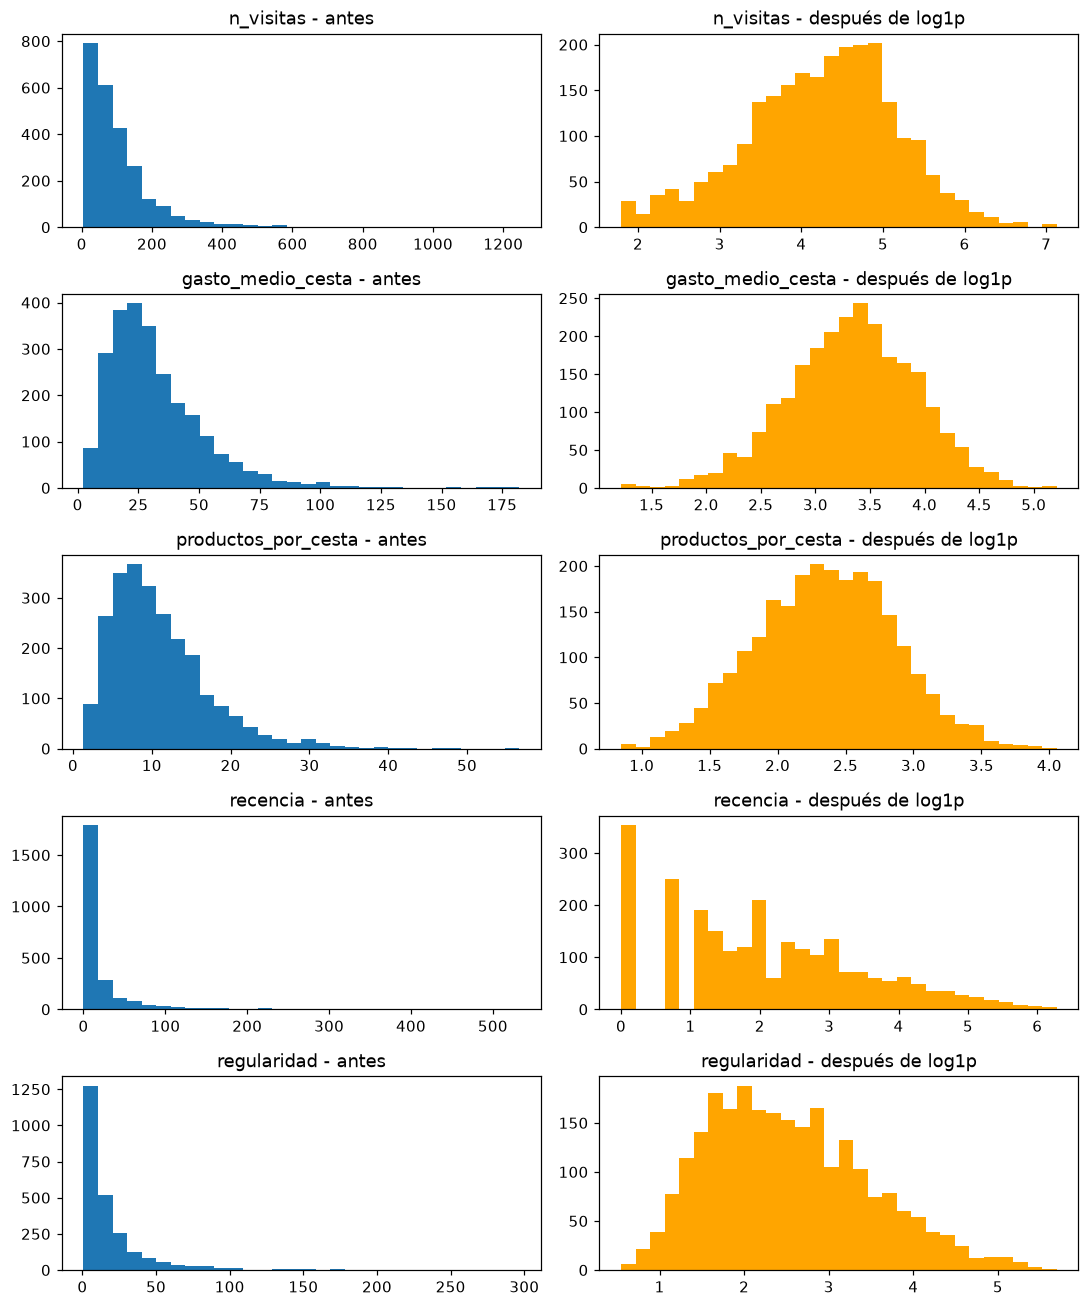

In [7]:
print("Asimetría de las variables:")
print(hogares.skew().round(2))
columnas_log = ["n_visitas", "gasto_medio_cesta", "productos_por_cesta", "recencia", "regularidad"]
for columna in columnas_log:
    hogares[columna] = np.log1p(hogares[columna])

fig, ejes = plt.subplots(5, 2, figsize=(10, 12))
for i, columna in enumerate(columnas_log):
    ejes[i, 0].hist(sin_escalar[columna], bins=30)
    ejes[i, 0].set_title(columna + " - antes")
    ejes[i, 1].hist(hogares[columna], bins=30, color="orange")
    ejes[i, 1].set_title(columna + " - después de log1p")
plt.tight_layout()
plt.savefig(figuras / "01_histogramas_transformaciones.png", dpi=150)
plt.show()

## 7. Correlación
Quitamos productos por cesta (0,92 con gasto medio) y regularidad (−0,92 con visitas). Nos quedan 7 variables.

                     n_visitas  gasto_medio_cesta  ...  pct_fresco  pct_descuento
n_visitas                 1.00              -0.06  ...       -0.07          -0.05
gasto_medio_cesta        -0.06               1.00  ...        0.11          -0.10
recencia                 -0.54              -0.03  ...        0.06           0.05
variedad                  0.77               0.45  ...        0.02          -0.10
pct_marca_propia          0.03              -0.22  ...        0.08           0.36
productos_por_cesta      -0.04               0.92  ...        0.14           0.02
regularidad              -0.92              -0.04  ...        0.05           0.04
pct_fresco               -0.07               0.11  ...        1.00           0.15
pct_descuento            -0.05              -0.10  ...        0.15           1.00

[9 rows x 9 columns]
Gasto medio / productos por cesta: 0.922
Visitas / regularidad: -0.918


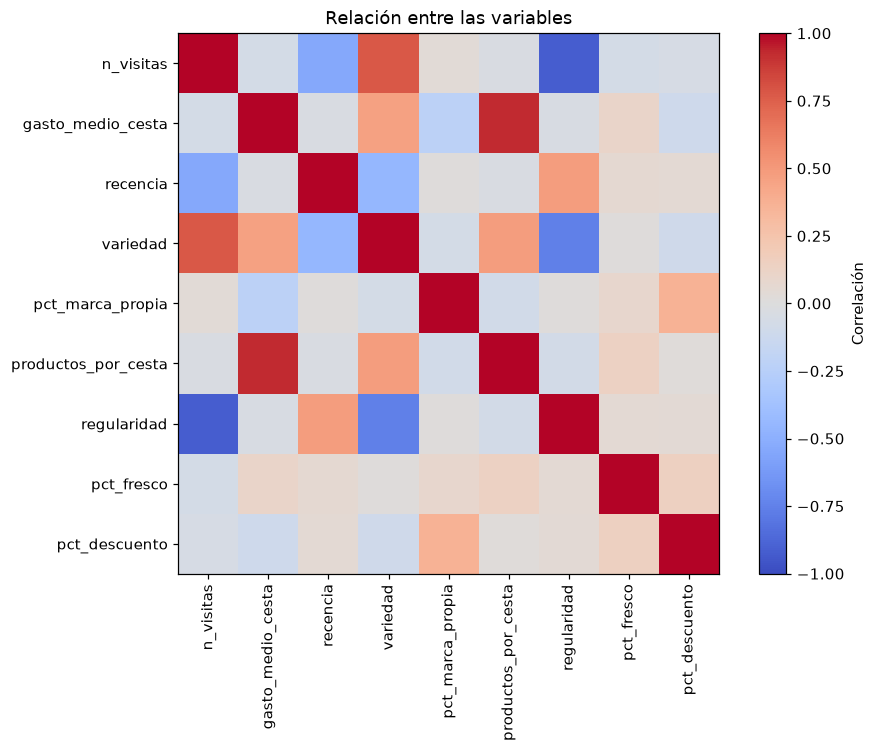

In [8]:
correlacion = hogares.corr()
print(correlacion.round(2))
print("Gasto medio / productos por cesta:", round(correlacion.loc["gasto_medio_cesta", "productos_por_cesta"], 3))
print("Visitas / regularidad:", round(correlacion.loc["n_visitas", "regularidad"], 3))
plt.figure(figsize=(9, 7))
plt.imshow(correlacion, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(hogares.columns)), hogares.columns, rotation=90)
plt.yticks(range(len(hogares.columns)), hogares.columns)
plt.colorbar(label="Correlación")
plt.title("Relación entre las variables")
plt.tight_layout()
plt.savefig(figuras / "01_correlaciones.png", dpi=150)
plt.show()

hogares = hogares.drop(columns=["productos_por_cesta", "regularidad"])
sin_escalar = sin_escalar.drop(columns=["productos_por_cesta", "regularidad"])

## 8. Escalar y guardar
Escalamos con `StandardScaler` y guardamos `hogares.csv` (para los mapas) y `hogares_sin_escalar.csv` (para describir los segmentos).

In [ ]:
columnas = ["n_visitas", "gasto_medio_cesta", "recencia", "variedad",
            "pct_marca_propia", "pct_fresco", "pct_descuento"]
hogares = hogares[columnas]
sin_escalar = sin_escalar[columnas]
hogares_escalados = pd.DataFrame(StandardScaler().fit_transform(hogares),
                                 index=hogares.index, columns=columnas)
hogares_escalados.reset_index().to_csv(salidas / "hogares.csv", index=False)
sin_escalar.reset_index().to_csv(salidas / "hogares_sin_escalar.csv", index=False)
print("Entrega final:", len(hogares), "hogares y", len(columnas), "variables")
print("Valores medios después de escalar:")
print(hogares_escalados.mean().round(6))

Entrega final: 2475 hogares y 7 variables
Valores medios después de escalar:
n_visitas            0.0
gasto_medio_cesta    0.0
recencia            -0.0
variedad            -0.0
pct_marca_propia    -0.0
pct_fresco          -0.0
pct_descuento       -0.0
dtype: float64


## Resultado
2.475 hogares y 7 variables.